In [141]:
import pandas as pd
import numpy as np

In [142]:
from behavioral_ml.etl import load_data

mouse_df, key_df = load_data("../raw_kmt_dataset")

mouse_df.sort_index()

Event  \
User ID Is Genuine Test ID Event ID Movement ID                 
1       False      1       0        1                movement   
                           1        <NA>         left release   
                           2        1                movement   
                           3        1                movement   
                           4        1                movement   
...                                                       ...   
88      True       10      119      4                movement   
                           120      4                movement   
                           121      4                movement   
                           122      4                movement   
                           123      <NA>           left press   

                                                                Coordinates  \
User ID Is Genuine Test ID Event ID Movement ID                               
1       False      1       0        1                             [386, 91]   
                           1        <NA>           [386, 91.00000000000001]   
                           2        1                             [386, 92]   
                           3        1                             [387, 92]   
                           4        1                             [387, 93]   
...                                                                     ...   
88      True       10      119      4                         [387.0, 93.0]   
                           120      4                         [387.0, 92.0]   
                           121      4                         [387.0, 91.0]   
                           122      4                         [386.0, 90.0]   
                           123      <NA>         [386.0, 90.00000000000004]   

                                                             Epoch  
User ID Is Genuine Test ID Event ID Movement ID                     
1       False      1       0        1            1644175528.359473  
                           1        <NA>         1644175528.408747  
                           2        1            1644175528.421404  
                           3        1            1644175528.471485  
                           4        1            1644175528.496569  
...                                                            ...  
88      True       10      119      4            1649930368.457277  
                           120      4            1649930368.469285  
                           121      4            1649930368.481287  
                           122      4            1649930368.493289  
                           123      <NA>         1649930368.959408  

[644405 rows x 3 columns]

In [143]:
from behavioral_ml.features import add_kinematics, derive_movement_features

movement_features = mouse_df.pipe(add_kinematics).pipe(derive_movement_features)
k_mouse = mouse_df.pipe(add_kinematics)
movement_features

Path  Duration      V_mean  \
User ID Is Genuine Test ID Movement ID                                      
1       False      1       1            1343.113141  4.379695  563.215712   
                           2             738.613262  2.388698  876.685545   
                           3               0.000000       0.0        <NA>   
                           4              12.650282  0.808292   84.528703   
                           5               2.000000  0.382143    41.44263   
...                                             ...       ...         ...   
88      True       9       3             124.636904  0.501125  333.118094   
                           4             333.845207  0.940235  428.219272   
                   10      2             284.718996  0.579148    749.5198   
                           3             149.104910  0.502131  415.211592   
                           4             321.448876  0.843216  534.478992   

                                              V_std      V_q10    V_median  \
User ID Is Genuine Test ID Movement ID                                       
1       False      1       1            1314.167668  27.052246  249.859253   
                           2            1301.098523  15.789417  388.086299   
                           3                   <NA>       <NA>        <NA>   
                           4              58.135322   3.581197   80.103737   
                           5               54.78313  10.452612    41.44263   
...                                             ...        ...         ...   
88      True       9       3             424.340823  39.991724  142.235901   
                           4             389.434858  42.224417  348.652488   
                   10      2            1045.230352  76.907494  186.274779   
                           3              437.80769  74.972835   235.61167   
                           4             520.367434  39.992525  343.692256   

                                              V_q90     a_min_q20  \
User ID Is Genuine Test ID Movement ID                              
1       False      1       1            1000.277566 -31867.512237   
                           2            2372.865641 -72105.226123   
                           3                   <NA>          <NA>   
                           4             168.297813  -3011.296614   
                           5              72.432649   -209.578311   
...                                             ...           ...   
88      True       9       3             961.056837 -18994.833415   
                           4            1044.219752 -24909.766932   
                   10      2              3027.4525  -32566.30345   
                           3            1238.421955 -22602.028504   
                           4            1186.706815 -38986.377011   

                                          a_plus_q80  Displacement  \
User ID Is Genuine Test ID Movement ID                               
1       False      1       1            30209.760825    507.575610   
                           2            57453.618975    670.543809   
                           3                    <NA>      0.000000   
                           4             7631.104061     11.401754   
                           5                    <NA>      2.000000   
...                                              ...           ...   
88      True       9       3            19134.699933    115.520561   
                           4             24519.34052    212.960090   
                   10      2            24569.768618    274.242593   
                           3            17931.512612    138.437712   
                           4            41187.360014    213.740497   

                                        Straightness  V_real_mean  
User ID Is Genuine Test ID Movement ID                             
1       False      1       1                2.646134   306.668178  
                 

In [144]:
test_level_features = movement_features.groupby(level=["User ID", "Is Genuine", "Test ID"]).agg(
    Path_mean = ("Path", "mean"),
    Path_std = ("Path", "std"),
    Duration_mean = ("Duration", "mean"),
    Duration_std = ("Duration", "std"),
    V_mean=("V_real_mean", "mean"),
    V_std=("V_real_mean", "std"),
    V_median=("V_real_mean", "median"),
    Straightness_mean=("Straightness", "mean"),
    Straightness_std=("Straightness", "std"),
    Straightness_median=("Straightness", "median"),
    a_min_mean=("a_min_q20", "mean"),
    a_plus_mean=("a_plus_q80", "mean")
)
test_level_features

Path_mean    Path_std  Duration_mean  \
User ID Is Genuine Test ID                                          
1       False      1        274.249126  422.472827        1.10254   
                   2        276.941280  256.981329       1.790157   
                   3        462.670278  293.008713       1.510187   
                   4        177.495742  113.427165       0.634689   
                   5        234.525456  261.080824       0.834561   
...                                ...         ...            ...   
88      True       6        330.632203  170.795719        0.95349   
                   7        336.074760  177.894167       0.752858   
                   8        262.427028  113.017935       0.857883   
                   9        249.229793  110.184742       0.692508   
                   10       251.757594   90.776931       0.641499   

                            Duration_std      V_mean       V_std    V_median  \
User ID Is Genuine Test ID                                                     
1       False      1            1.297997  193.324799    191.4886  168.511629   
                   2            1.575939  180.819024   91.076198   173.19937   
                   3            0.998557  332.795623  111.181444  299.530454   
                   4            0.267685  270.479865  108.191208  256.234249   
                   5            0.873685   323.70584  264.607996  262.455425   
...                                  ...         ...         ...         ...   
88      True       6            0.184238   339.77184  142.016136  397.081502   
                   7            0.423177  463.439243    78.06806  448.258181   
                   8            0.285103  299.456443   71.068765  304.022371   
                   9            0.224911  352.796688  102.966834  355.065837   
                   10           0.178887  389.926161   97.628055  381.217633   

                            Straightness_mean  Straightness_std  \
User ID Is Genuine Test ID                                        
1       False      1                 1.717724          0.859318   
                   2                 1.917074          0.883825   
                   3                 2.706294          1.584556   
                   4                 2.069663          2.199501   
                   5                 2.720395          4.000787   
...                                       ...               ...   
88      True       6                 3.018705          3.125367   
                   7                 1.356928          0.587994   
                   8                 1.308250          0.341193   
                   9                 1.225987          0.296834   
                   10                1.206392          0.258399   

                            Straightness_median    a_min_mean   a_plus_mean  
User ID Is Genuine Test ID                                                   
1       False      1                   1.114098 -31066.416475  29032.348312  
                   2                   1.469194 -21564.360267  23625.258934  
                   3                   2.250735  -38270.97847  37162.957878  
                   4                   1.116929 -24680.760742   22708.88576  
                   5                   1.217430 -34156.522987   104635.3775  
...                                         ...           ...           ...  
88      True       6                   1.610011  -29174.43323  35778.709481  
                   7                   1.025505 -51418.434442  44561.567282  
                   8                   1.113347 -24698.719215  31132.089234  
                   9                   1.078915 -24456.745186  21521.313054  
                   10                  1.077054 -31384.902988  27896.213748  

[1760 rows x 12 columns]

In [145]:
k_mouse.loc[(1, False, 1)]

/var/folders/cy/vtgqm1615tnblh56mvrz5ww00000gn/T/ipykernel_28246/3661447029.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  k_mouse.loc[(1, False, 1)]


,,Event,Coordinates,Epoch,X,Y,dX,dY,dS,dT,V,A,Jerk
Event ID,Movement ID,,,,,,,,,,,,
0,1,movement,"[386, 91]",1644175528.359473,386.0,91.0,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>
1,<NA>,left release,"[386, 91.00000000000001]",1644175528.408747,386.0,91.0,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>
2,1,movement,"[386, 92]",1644175528.421404,386.0,92.0,0.0,1.0,1.0,0.061931,16.14703,<NA>,<NA>
3,1,movement,"[387, 92]",1644175528.471485,387.0,92.0,1.0,0.0,1.0,0.050081,19.967552,76.286466,<NA>
4,1,movement,"[387, 93]",1644175528.496569,387.0,93.0,0.0,1.0,1.0,0.025084,39.865641,793.250118,28582.215868
...,...,...,...,...,...,...,...,...,...,...,...,...,...
455,11,movement,"[373, 116]",1644175557.405239,373.0,116.0,0.0,-1.0,1.0,0.01201,83.261618,-6926.71947,-449350.736376
456,11,movement,"[373, 115]",1644175557.417238,373.0,115.0,0.0,-1.0,1.0,0.012,83.334406,6.065775,577739.541954
457,11,movement,"[373, 113]",1644175557.443276,373.0,113.0,0.0,-2.0,2.0,0.026038,76.811017,-250.534073,-9854.847689


In [146]:
df = mouse_df.copy()
click_features = df.loc[df["Event"] != "movement"]
df[["Button", "Button Event"]] = click_features["Event"].str.split(" ", expand=True)
df.groupby(by=["Button", "Button Event"]).count()

Event  Coordinates  Epoch
Button      Button Event                           
left        press         11563        11563  11563
            release       11475        11475  11475
mouse4      press             3            3      3
            release           3            3      3
right       press            71           71     71
            release          71           71     71
scrolldown  press            34           34     34
            release          34           34     34
scrollleft  press             1            1      1
            release           1            1      1
scrollright press            10           10     10
            release          11           11     11
scrollup    press           125          125    125
            release         122          122    122

In [147]:
click_features = df.loc[df["Event"] != "movement"]
click_features.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Button"
    ])[["Button","Button Event"]].shift(0)

Button Button Event
User ID Is Genuine Test ID Event ID Movement ID                    
1       True       1       55       <NA>          left        press
                           56       <NA>          left      release
                           74       <NA>          left        press
                           78       <NA>          left      release
                           83       <NA>          left        press
...                                                ...          ...
88      False      10      159      <NA>          left        press
                           160      <NA>          left      release
                           191      <NA>          left        press
                           192      <NA>          left      release
                           294      <NA>          left        press

[23524 rows x 2 columns]

In [148]:
MOUSE_BUTTONS = ["left", "right", "mouse4"]

button_features = df.loc[(df["Event"] != "movement") & df["Button"].isin(MOUSE_BUTTONS)]
g = button_features.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Button"
    ])
button_features["Next Button Event"] = g["Button Event"].shift(-1)
button_features["Next Epoch"] = g["Epoch"].shift(-1)

valid_press = (button_features["Button Event"] == "press") & (button_features["Next Button Event"] == "release")
button_features["Dwell Time"] = np.where(valid_press, button_features["Next Epoch"] - button_features["Epoch"], np.nan)
button_features

Event  \
User ID Is Genuine Test ID Event ID Movement ID                 
1       True       1       55       <NA>           left press   
                           56       <NA>         left release   
                           74       <NA>           left press   
                           78       <NA>         left release   
                           83       <NA>           left press   
...                                                       ...   
88      False      10      159      <NA>           left press   
                           160      <NA>         left release   
                           191      <NA>           left press   
                           192      <NA>         left release   
                           294      <NA>           left press   

                                                                 Coordinates  \
User ID Is Genuine Test ID Event ID Movement ID                                
1       True       1       55       <NA>           [307, 383.00000000000006]   
                           56       <NA>           [307, 383.00000000000006]   
                           74       <NA>                          [318, 312]   
                           78       <NA>                          [319, 305]   
                           83       <NA>                          [324, 291]   
...                                                                      ...   
88      False      10      159      <NA>         [422.0, 380.99999999999994]   
                           160      <NA>         [422.0, 380.99999999999994]   
                           191      <NA>                      [288.0, 285.0]   
                           192      <NA>                      [288.0, 285.0]   
                           294      <NA>          [376.0, 88.99999999999999]   

                                                             Epoch Button  \
User ID Is Genuine Test ID Event ID Movement ID                             
1       True       1       55       <NA>         1644173828.782241   left   
                           56       <NA>         1644173828.856247   left   
                           74       <NA>         1644173829.122411   left   
                           78       <NA>         1644173829.186461   left   
                           83       <NA>         1644173829.428797   left   
...                                                            ...    ...   
88      False      10      159      <NA>         1649151715.149565   left   
                           160      <NA>         1649151715.375268   left   
                           191      <NA>         1649151718.584617   left   
                           192      <NA>         1649151718.812721   left   
                           294      <NA>         1649151788.412875   left   

                                                Button Event  \
User ID Is Genuine Test ID Event ID Movement ID                
1       True       1       55       <NA>               press   
                           56       <NA>             release   
                           74       <NA>               press   
                           78       <NA>             release   
                           83       <NA>               press   
...                                                      ...   
88      False      10      159      <NA>               press   
                           160      <NA>             release   
                           191      <NA>               press   
                           192      <NA>             release   
                           294      <NA>               press   

                                                Next Button Event  \
User ID Is Genuine Test ID Event ID Movement ID                     
1       True       1       55       <NA>                  release   
                           56       <NA>                    press   
                           74       <NA>                  

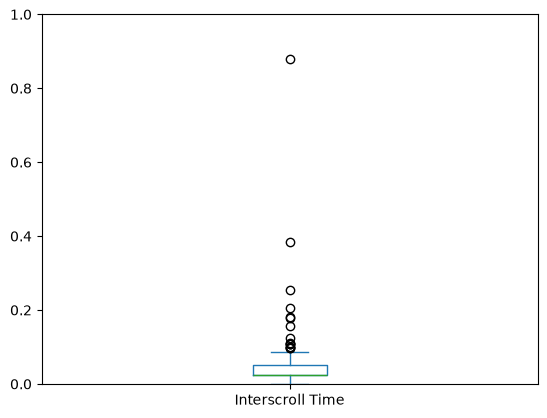

In [149]:
SCROLL_TYPES = [
    "scrollup",
    "scrolldown"
]
LEVELS = [
    "User ID",
    "Is Genuine",
    "Test ID"
]


scroll = df.loc[df["Button"].isin(SCROLL_TYPES) & df["Button Event"].eq("press") & (df["Event"] != "movement")]
g = scroll.groupby(level=LEVELS)

scroll["Interscroll Time"] = g["Epoch"].diff()
ax = scroll["Interscroll Time"].plot(kind="box")
ax.set_ylim(ymin=0, ymax=1);

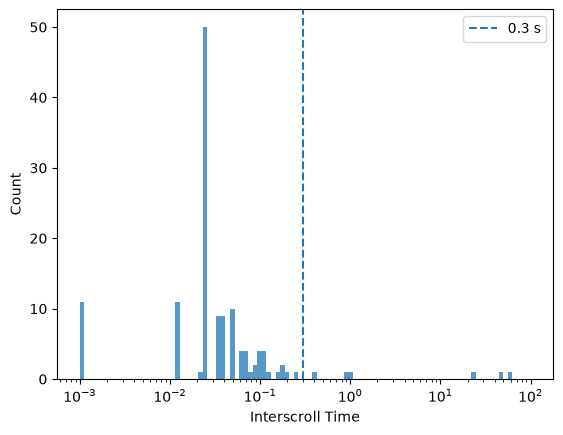

In [150]:
import seaborn as sns
import matplotlib.pyplot as plt

bins = np.logspace(
    np.log10(0.001),
    np.log10(100),
    100,
)

sns.histplot(scroll["Interscroll Time"], bins=bins)
plt.xscale("log")

plt.axvline(0.3, linestyle="--", label="0.3 s")

plt.legend();

In [151]:
threshold = 0.3  # example only

scroll["New Burst"] = (
    scroll["Interscroll Time"].isna()
    | scroll["Interscroll Time"].gt(threshold)
)

scroll["Burst ID"] = (
    scroll.groupby(level=LEVELS, sort=False)["New Burst"]
    .cumsum()
)

scroll

Event  \
User ID Is Genuine Test ID Event ID Movement ID                     
2       False      9       352      <NA>         scrolldown press   
                           360      <NA>         scrolldown press   
                           371      <NA>         scrolldown press   
3       False      9       247      <NA>         scrolldown press   
                           249      <NA>         scrolldown press   
...                                                           ...   
88      True       1       91       <NA>           scrollup press   
                           93       <NA>           scrollup press   
                           97       <NA>           scrollup press   
                           99       <NA>           scrollup press   
                           103      <NA>           scrollup press   

                                                                 Coordinates  \
User ID Is Genuine Test ID Event ID Movement ID                                
2       False      9       352      <NA>          [219.0, 93.00000000000003]   
                           360      <NA>         [332.0, 146.00000000000003]   
                           371      <NA>         [434.0, 136.99999999999997]   
3       False      9       247      <NA>          [277.0, 91.99999999999999]   
                           249      <NA>          [277.0, 91.99999999999999]   
...                                                                      ...   
88      True       1       91       <NA>         [492.99999999999994, 556.0]   
                           93       <NA>         [492.99999999999994, 556.0]   
                           97       <NA>         [492.99999999999994, 556.0]   
                           99       <NA>         [492.99999999999994, 556.0]   
                           103      <NA>         [492.99999999999994, 556.0]   

                                                             Epoch  \
User ID Is Genuine Test ID Event ID Movement ID                      
2       False      9       352      <NA>         1644185645.628699   
                           360      <NA>         1644185645.702723   
                           371      <NA>          1644185645.81218   
3       False      9       247      <NA>         1644185679.179201   
                           249      <NA>         1644185679.204164   
...                                                            ...   
88      True       1       91       <NA>         1649929693.672558   
                           93       <NA>         1649929693.696567   
                           97       <NA>         1649929693.721573   
                           99       <NA>         1649929693.773583   
                           103      <NA>          1649929693.79859   

                                                     Button Button Event  \
User ID Is Genuine Test ID Event ID Movement ID                            
2       False      9       352      <NA>         scrolldown        press   
                           360      <NA>         scrolldown        press   
                           371      <NA>         scrolldown        press   
3       False      9       247      <NA>         scrolldown        press   
                           249      <NA>         scrolldown        press   
...                                                     ...          ...   
88      True       1       91       <NA>           scrollup        press   
                           93       <NA>           scrollup        press   
                           97       <NA>           scrollup        press   
                           99       <NA>           scrollup        press   
                           103      <NA>           scrollup        press   

                                                 Interscroll Time  New Burst  \
User ID Is Genuine Test ID Event ID Movement ID                                
2       False      9       352      <NA>                     

In [152]:
mouse_df = (df
            .join(scroll[["Interscroll Time", "Burst ID"]])
            .join(button_features["Dwell Time"])
            )

In [153]:
test_level_clicks = mouse_df.groupby(level=LEVELS).agg(
    Burst_count=("Burst ID", "max"),
    Dwell_Time_mean=("Dwell Time", "mean"),
    Dwell_Time_std=("Dwell Time", "std"),
    Click_count=("Dwell Time", "count")
)
test_level_clicks.fillna(0, inplace=True)

Burst_count  Dwell_Time_mean  Dwell_Time_std  \
User ID Is Genuine Test ID                                                 
1       False      1                  0         0.102698        0.021886   
                   2                  0         0.133980        0.010070   
                   3                  0         0.095714        0.019424   
                   4                  0         0.220024        0.010642   
                   5                  0         0.167220        0.046395   
...                                 ...              ...             ...   
88      True       6                  0         0.227391        0.002516   
                   7                  0         0.229058        0.001411   
                   8                  0         0.224055        0.008493   
                   9                  0         0.217556        0.000707   
                   10                 0         0.223543        0.010595   

                            Click_count  
User ID Is Genuine Test ID               
1       False      1                  6  
                   2                  6  
                   3                  5  
                   4                  6  
                   5                  3  
...                                 ...  
88      True       6                  3  
                   7                  2  
                   8                  2  
                   9                  2  
                   10                 2  

[1760 rows x 4 columns]

In [154]:
key_df.head()

Key     Event              Epoch
User ID Is Genuine Test ID Event ID                                    
1       True       1       0         shift   pressed   1644173829.98174
                           1             m   pressed  1644173830.121021
                           2         shift  released   1644173830.16947
                           3             m  released   1644173830.21818
                           4             r   pressed  1644173830.293582

In [155]:
key_df["Key"].unique()

<ArrowStringArray>
[          'shift',               'm',               'r',               's',
        'spacebar',               'w',               'e',       'backspace',
               'l',               'i',             'tab',               '4',
               '2',               '8',               '9',               '1',
               '5',               '0',               '6',               '7',
               '3',          'rshift',         'numpad4',         'numpad2',
         'numpad8',         'numpad9',         'numpad1',         'numpad5',
         'numpad0',         'numpad6',         'numpad7',         'numpad3',
        'capslock', 'numpadsubstract',               '.',               'j',
               ',',               'h',               'd',               't',
               'a',               'y',               'u',               'o',
         'numlock',               'f',           'enter',               'n',
               'g',               '-',               '`',

In [156]:
NUMPAD_KEYS = [key for key in key_df["Key"].unique() if key.startswith("num")]

ARROW_KEYS = ["up", "down", "right", "left"]
CORRECTION_KEYS = ["delete", "backspace"]
SHIFT_KEYS = ["shift", "rshift"]

In [157]:
shiftless_key_df = key_df.loc[~key_df["Key"].isin(SHIFT_KEYS)]
g = shiftless_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])
key_df["Next Event"] = g["Event"].shift(-1)
key_df["Next Epoch"] = g["Epoch"].shift(-1)

valid_press = (key_df["Event"] == "pressed") & (key_df["Next Event"] == "released")
key_df["Dwell Time"] = np.where(valid_press, key_df["Next Epoch"] - key_df["Epoch"], np.nan)
key_df

Key     Event              Epoch  \
User ID Is Genuine Test ID Event ID                                       
1       True       1       0         shift   pressed   1644173829.98174   
                           1             m   pressed  1644173830.121021   
                           2         shift  released   1644173830.16947   
                           3             m  released   1644173830.21818   
                           4             r   pressed  1644173830.293582   
...                                    ...       ...                ...   
88      False      10      78            2   pressed  1649151779.791193   
                           79            2  released  1649151779.888461   
                           80            3   pressed  1649151780.045138   
                           81            3  released  1649151780.156547   
                           82          tab  released  1649151787.129236   

                                    Next Event         Next Epoch  Dwell Time  
User ID Is Genuine Test ID Event ID                                            
1       True       1       0               NaN               <NA>         NaN  
                           1          released   1644173830.21818    0.097159  
                           2               NaN               <NA>         NaN  
                           3           pressed  1644173832.633649         NaN  
                           4          released  1644173830.355541    0.061959  
...                                        ...                ...         ...  
88      False      10      78         released  1649151779.888461    0.097268  
                           79              NaN               <NA>         NaN  
                           80         released  1649151780.156547    0.111409  
                           81              NaN               <NA>         NaN  
                           82              NaN               <NA>         NaN  

[172563 rows x 6 columns]

In [158]:
shiftless_key_df = key_df.loc[(~key_df["Key"].isin(SHIFT_KEYS)) & (key_df["Event"] == "pressed")]
g = shiftless_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    ])
key_df["Next Pressed Key"] = g["Key"].shift(-1)
key_df["Next Pressed Epoch"] = g["Epoch"].shift(-1)

key_df["Flight Time"] = key_df["Next Pressed Epoch"] - key_df["Epoch"]
# valid_press = (key_df["Event"] == "pressed") & (key_df["Next Event"] == "released")
# key_df["Dwell Time"] = np.where(valid_press, key_df["Next Epoch"] - key_df["Epoch"], np.nan)
key_df

Key     Event              Epoch  \
User ID Is Genuine Test ID Event ID                                       
1       True       1       0         shift   pressed   1644173829.98174   
                           1             m   pressed  1644173830.121021   
                           2         shift  released   1644173830.16947   
                           3             m  released   1644173830.21818   
                           4             r   pressed  1644173830.293582   
...                                    ...       ...                ...   
88      False      10      78            2   pressed  1649151779.791193   
                           79            2  released  1649151779.888461   
                           80            3   pressed  1649151780.045138   
                           81            3  released  1649151780.156547   
                           82          tab  released  1649151787.129236   

                                    Next Event         Next Epoch  Dwell Time  \
User ID Is Genuine Test ID Event ID                                             
1       True       1       0               NaN               <NA>         NaN   
                           1          released   1644173830.21818    0.097159   
                           2               NaN               <NA>         NaN   
                           3           pressed  1644173832.633649         NaN   
                           4          released  1644173830.355541    0.061959   
...                                        ...                ...         ...   
88      False      10      78         released  1649151779.888461    0.097268   
                           79              NaN               <NA>         NaN   
                           80         released  1649151780.156547    0.111409   
                           81              NaN               <NA>         NaN   
                           82              NaN               <NA>         NaN   

                                    Next Pressed Key  Next Pressed Epoch  \
User ID Is Genuine Test ID Event ID                                        
1       True       1       0                     NaN                <NA>   
                           1                       r   1644173830.293582   
                           2                     NaN                <NA>   
                           3                     NaN                <NA>   
                           4                       s   1644173830.480926   
...                                              ...                 ...   
88      False      10      78                      3   1649151780.045138   
                           79                    NaN                <NA>   
                           80                    NaN                <NA>   
                           81                    NaN                <NA>   
                           82                    NaN                <NA>   

                                     Flight Time  
User ID Is Genuine Test ID Event ID               
1       True       1       0                <NA>  
                           1            0.172561  
                           2                <NA>  
                           3                <NA>  
                           4            0.187344  
...                                          ...  
88      False      10      78           0.253945  
                           79               <NA>  
                           80               <NA>  
                           81               <NA>  
                           82               <NA>  

[172563 rows x 9 columns]

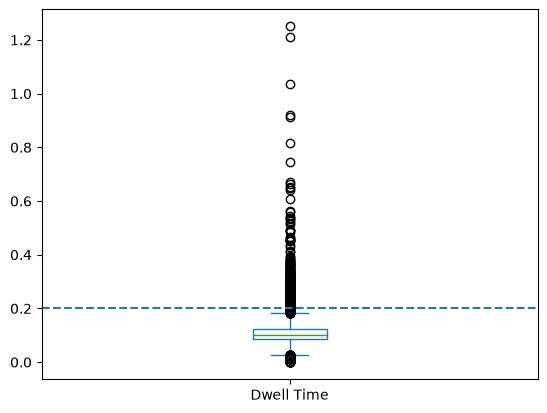

In [159]:
ax = key_df["Dwell Time"].plot(kind="box")
plt.axhline(0.2, linestyle="--", label="0.3 s");

In [160]:
threshold = 0.3

key_df[key_df["Dwell Time"] > threshold]["Key"].value_counts()

Key
lctrl        24
capslock      7
6             7
7             7
4             7
1             6
rctrl         6
enter         6
8             5
-             5
backspace     4
2             4
l             3
spacebar      3
numpad2       2
i             2
right         2
a             2
left          2
9             2
k             1
numpad9       1
numpad3       1
m             1
s             1
3             1
h             1
numpad6       1
g             1
0             1
n             1
'             1
super         1
alt           1
z             1
Name: count, dtype: int64

In [161]:
key_df

Key     Event              Epoch  \
User ID Is Genuine Test ID Event ID                                       
1       True       1       0         shift   pressed   1644173829.98174   
                           1             m   pressed  1644173830.121021   
                           2         shift  released   1644173830.16947   
                           3             m  released   1644173830.21818   
                           4             r   pressed  1644173830.293582   
...                                    ...       ...                ...   
88      False      10      78            2   pressed  1649151779.791193   
                           79            2  released  1649151779.888461   
                           80            3   pressed  1649151780.045138   
                           81            3  released  1649151780.156547   
                           82          tab  released  1649151787.129236   

                                    Next Event         Next Epoch  Dwell Time  \
User ID Is Genuine Test ID Event ID                                             
1       True       1       0               NaN               <NA>         NaN   
                           1          released   1644173830.21818    0.097159   
                           2               NaN               <NA>         NaN   
                           3           pressed  1644173832.633649         NaN   
                           4          released  1644173830.355541    0.061959   
...                                        ...                ...         ...   
88      False      10      78         released  1649151779.888461    0.097268   
                           79              NaN               <NA>         NaN   
                           80         released  1649151780.156547    0.111409   
                           81              NaN               <NA>         NaN   
                           82              NaN               <NA>         NaN   

                                    Next Pressed Key  Next Pressed Epoch  \
User ID Is Genuine Test ID Event ID                                        
1       True       1       0                     NaN                <NA>   
                           1                       r   1644173830.293582   
                           2                     NaN                <NA>   
                           3                     NaN                <NA>   
                           4                       s   1644173830.480926   
...                                              ...                 ...   
88      False      10      78                      3   1649151780.045138   
                           79                    NaN                <NA>   
                           80                    NaN                <NA>   
                           81                    NaN                <NA>   
                           82                    NaN                <NA>   

                                     Flight Time  
User ID Is Genuine Test ID Event ID               
1       True       1       0                <NA>  
                           1            0.172561  
                           2                <NA>  
                           3                <NA>  
                           4            0.187344  
...                                          ...  
88      False      10      78           0.253945  
                           79               <NA>  
                           80               <NA>  
                           81               <NA>  
                           82               <NA>  

[172563 rows x 9 columns]

In [162]:
pressed_key_df = key_df[(key_df["Event"] == "pressed") & key_df["Key"].isin(["capslock", "enter", "spacebar"])]
other_keys_test_level = pressed_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()
# other_keys_test_level.fillna(0, inplace=True)

In [163]:
arrow_key_df = key_df[(key_df["Event"] == "pressed") & key_df["Key"].isin(ARROW_KEYS)]
arrow_keys_test_level = arrow_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()
arrow_keys_test_level = arrow_keys_test_level.sum(axis=1).rename("arrows").astype("int")

In [164]:
correction_key_df = key_df[(key_df["Event"] == "pressed") & key_df["Key"].isin(CORRECTION_KEYS)]
correction_keys_test_level = correction_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()

In [165]:
numpad_key_df = key_df[(key_df["Event"] == "pressed") & key_df["Key"].isin(NUMPAD_KEYS)]
numpad_keys_test_level = numpad_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()
numpad_keys_test_level = numpad_keys_test_level.sum(axis=1).rename("numpad").astype("int")

In [166]:
released_key_df = key_df[(key_df["Event"] == "released") & key_df["Key"].isin(["tab"])]
tab_test_level = released_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()
tab_test_level.fillna(0, inplace=True)

Key                         tab
User ID Is Genuine Test ID     
1       False      3          2
                   5          5
                   7          4
                   8          4
                   10         4
...                         ...
88      True       6          4
                   7          4
                   8          4
                   9          4
                   10         4

[901 rows x 1 columns]

In [167]:
key_test_level = key_df.groupby(level=LEVELS).agg(
    Dwell_mean=("Dwell Time", "mean"),
    Dwell_std=("Dwell Time", "std"),
    Flight_mean=("Flight Time", "mean"),
    Flight_std=("Flight Time", "std")
)

In [168]:
test_level_features = (
    test_level_clicks
    .join(key_test_level)
    .join(other_keys_test_level)
    .join(tab_test_level)
    .join(correction_keys_test_level)
    .join(numpad_keys_test_level)
    .join(arrow_keys_test_level)
)

In [169]:
test_level_features.fillna({
    "enter": 0,
    "spacebar": 0,
    "tab": 0,
    "capslock": 0,
    "arrows": 0,
    "numpad": 0,
    "delete": 0,
    "backspace": 0
}, inplace=True)

Burst_count  Dwell_Time_mean  Dwell_Time_std  \
User ID Is Genuine Test ID                                                 
1       False      1                  0         0.102698        0.021886   
                   2                  0         0.133980        0.010070   
                   3                  0         0.095714        0.019424   
                   4                  0         0.220024        0.010642   
                   5                  0         0.167220        0.046395   
...                                 ...              ...             ...   
88      True       6                  0         0.227391        0.002516   
                   7                  0         0.229058        0.001411   
                   8                  0         0.224055        0.008493   
                   9                  0         0.217556        0.000707   
                   10                 0         0.223543        0.010595   

                            Click_count  Dwell_mean  Dwell_std  Flight_mean  \
User ID Is Genuine Test ID                                                    
1       False      1                  6    0.082395   0.035348     0.587801   
                   2                  6    0.082632   0.017946     0.906589   
                   3                  5    0.073261   0.019089     0.583382   
                   4                  6    0.116213   0.015620     0.970226   
                   5                  3    0.166415   0.036365      0.53398   
...                                 ...         ...        ...          ...   
88      True       6                  3    0.141899   0.033368      0.84584   
                   7                  2    0.142011   0.035848     0.901577   
                   8                  2    0.139676   0.033284     0.831604   
                   9                  2    0.141942   0.037021     0.992893   
                   10                 2    0.143549   0.039058     0.826998   

                            Flight_std  capslock  enter  spacebar  tab  \
User ID Is Genuine Test ID                                               
1       False      1          0.753984       0.0    0.0       2.0  0.0   
                   2          0.986329       0.0    0.0       2.0  0.0   
                   3          0.797085       8.0    0.0       2.0  2.0   
                   4          1.249153       0.0    0.0       2.0  0.0   
                   5          0.699677       0.0    0.0       2.0  5.0   
...                                ...       ...    ...       ...  ...   
88      True       6          0.779117       0.0    0.0       2.0  4.0   
                   7          0.786469       0.0    0.0       3.0  4.0   
                   8          0.732379       0.0    0.0       2.0  4.0   
                   9          0.827139       2.0    0.0       2.0  4.0   
                   10          0.69335       0.0    0.0       2.0  4.0   

                            backspace  delete  numpad  arrows  
User ID Is Genuine Test ID                                     
1       False      1              0.0     0.0    23.0     0.0  
                   2              0.0     0.0     0.0     0.0  
                   3              2.0     0.0    25.0     0.0  
                   4              0.0     0.0     0.0     0.0  
                   5              3.0     0.0     0.0     0.0  
...                               ...     ...     ...     ...  
88      True       6              1.0     0.0     0.0     3.0  
                   7              1.0     0.0     0.0     0.0  
                   8              0.0     0.0     0.0     0.0  
                   9              1.0     0.0     0.0     0.0  
                   10             0.0     0.0     0.0     0.0  

[1760 rows x 16 columns]

In [170]:
X = [test_level_features.loc[(user_id)] for user_id in range(1, 89)]
y = [test_level_features.loc[(user_id)].index.get_level_values("Is Genuine") for user_id in range(1, 89)]

In [171]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer

pipeline = make_pipeline(
    DecisionTreeClassifier()
)

scores = []
for user_id in range(1,89):
    X_train, X_test, y_train, y_test = train_test_split(X[user_id-1], y[user_id-1], stratify=y[user_id-1], test_size=.25, random_state=42)

    pipeline.fit(X_train, y_train)
    scores.append(pipeline.score(X_test, y_test))

np.mean(scores), np.std(scores)

(np.float64(0.7999999999999999), np.float64(0.20225995873897262))

In [ ]:
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        max_iter=1000,
    ),
)

scores = []
for user_id in range(1,89):
    X_train, X_test, y_train, y_test = train_test_split(X[user_id-1], y[user_id-1], stratify=y[user_id-1], test_size=.2, random_state=42)

    model.fit(X_train, y_train)
    
    scores.append(model.score(X_test, y_test))

np.mean(scores), np.std(scores)

(np.float64(0.8920454545454546), np.float64(0.14978893552800074))

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, precision_score, recall_score

roc_cu

In [173]:
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Burst_count','Dwell_Time_mean','Dwell_Time_std',...,'delete','numpad', 'arrows']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of mis

In [174]:
import xgboost as xgb

pipeline = xgb.XGBClassifier(max_depth=2, )

scores = []
for user_id in range(1,89):
    X_train, X_test, y_train, y_test = train_test_split(X[user_id-1], y[user_id-1], stratify=y[user_id-1], test_size=.2, random_state=42)

    pipeline.fit(X_train, y_train)
    scores.append(pipeline.score(X_test, y_test))

np.mean(scores), np.std(scores)

(np.float64(0.8380681818181818), np.float64(0.1885944298954858))

In [175]:
pipeline.feature_importances_

array([0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
      dtype=float32)

In [176]:
pipeline.feature_names_in_

array(['Burst_count', 'Dwell_Time_mean', 'Dwell_Time_std', 'Click_count',
       'Dwell_mean', 'Dwell_std', 'Flight_mean', 'Flight_std', 'capslock',
       'enter', 'spacebar', 'tab', 'backspace', 'delete', 'numpad',
       'arrows'], dtype='<U15')

In [177]:
from sklearn.svm import SVC

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="rbf", gamma="auto", C=1),
)

scores = []
for user_id in range(1,89):
    X_train, X_test, y_train, y_test = train_test_split(X[user_id-1], y[user_id-1], stratify=y[user_id-1], test_size=.25, random_state=42)

    model.fit(X_train, y_train)
    scores.append(model.score(X_test, y_test))

np.mean(scores), np.std(scores)

(np.float64(0.859090909090909), np.float64(0.15999741733452766))

In [178]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="rbf", gamma="scale", C=1),
)

scores = []
for user_id in range(1,89):
    score = cross_val_score(
        model,
        X[user_id-1],
        y[user_id-1],
        cv=cv,
        n_jobs=1
    )
    scores.append(score.mean())

np.mean(scores), np.std(scores)

(np.float64(0.8647727272727272), np.float64(0.08262699966947949))

In [179]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=1),
)

scores = []
for user_id in range(1,89):
    score = cross_val_score(
        model,
        X[user_id-1],
        y[user_id-1],
        cv=cv,
        n_jobs=1
    )
    scores.append(score.mean())

np.mean(scores), np.std(scores)

(np.float64(0.8505681818181817), np.float64(0.08806451605274002))

For further improvement it is necessary to properly clean the data.
Let's write a cleaning function for usage with `apply` method on the data grouped on a test level.

In [ ]:
def clean_key_events(group):
    # DISTINCT_PRESSES_THRESHOLD = 0.3
    
    presses = []
    active_presses = {}
    for key, event, epoch in group[["Key", "Event", "Epoch"]].itertuples(index=False):
        if (event == "pressed") and (key not in active_presses):
            active_presses[key] = {
                "Key": key,
                "Down": epoch,
                "Epochs": [epoch]
            }
        elif (event == "released") and (key in active_presses):
            active_presses[key]["Up"] = epoch
            presses.append(active_presses.pop(key))
        elif (event == "pressed") and (key in active_presses):
            active_presses[key]["Epochs"].append(epoch)
        elif (event == "released") and (key not in active_presses):
            presses.append({
                "Key": key,
                "Down": epoch,
                "Epochs": [epoch],
                "Release Only": True
            })
    
    presses += active_presses.values()
    presses = sorted(presses, key=lambda x: x["Down"])

    presses = pd.DataFrame(presses)
    return presses

    

key_df = key_df.groupby(level=LEVELS).apply(clean_key_events)
key_df

Key          Down                Epochs  \
User ID Is Genuine Test ID                                                    
1       False      1       0      shift  1.644176e+09  [1644175533.9525526]   
                           1          m  1.644176e+09  [1644175534.0420332]   
                           2          r  1.644176e+09   [1644175534.257084]   
                           3          s  1.644176e+09  [1644175534.4087963]   
                           4   spacebar  1.644176e+09  [1644175534.5358133]   
...                                 ...           ...                   ...   
88      True       10      41         1  1.649930e+09  [1649930364.1611965]   
                           42         0  1.649930e+09   [1649930364.882375]   
                           43       tab  1.649930e+09   [1649930366.013663]   
                           44         2  1.649930e+09  [1649930366.3227415]   
                           45         3  1.649930e+09   [1649930366.718838]   

                                         Up Release Only  
User ID Is Genuine Test ID                                
1       False      1       0   1.644176e+09          NaN  
                           1   1.644176e+09          NaN  
                           2   1.644176e+09          NaN  
                           3   1.644176e+09          NaN  
                           4   1.644176e+09          NaN  
...                                     ...          ...  
88      True       10      41  1.649930e+09          NaN  
                           42  1.649930e+09          NaN  
                           43           NaN         True  
                           44  1.649930e+09          NaN  
                           45  1.649930e+09          NaN  

[84955 rows x 5 columns]

In [192]:
prolonged_key_df = key_df[key_df["Epochs"].transform(lambda x: len(x)>1)]

time_until_second_press = prolonged_key_df["Epochs"].transform(lambda x: x[1] - x[0]).rename("Time Until Second Press")

prolonged_key_df = prolonged_key_df.join(time_until_second_press)

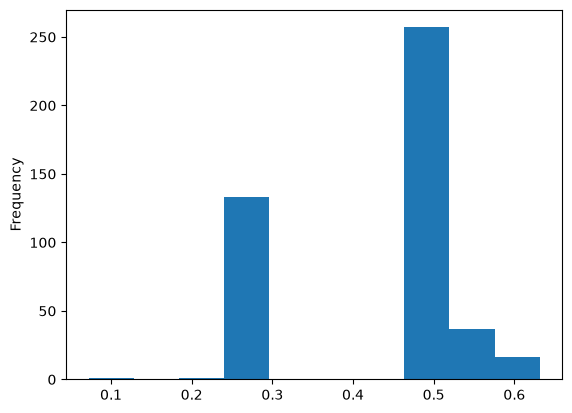

In [194]:
prolonged_key_df["Time Until Second Press"].plot(kind="hist");

In [ ]:
quicker_df = prolonged_key_df[prolonged_key_df["Time Until Second Press"] < 0.3]

Key          Down  \
User ID Is Genuine Test ID                               
12      False      10      58          s  1.649764e+09   
78      False      5       8      rshift  1.648897e+09   
                           16     rshift  1.648897e+09   
                   6       20          9  1.649074e+09   
                   7       21  backspace  1.649087e+09   
...                                  ...           ...   
88      True       5       11      shift  1.649930e+09   
                   6       11      shift  1.649930e+09   
                   7       11      shift  1.649930e+09   
                   8       11      shift  1.649930e+09   
                   10      11      shift  1.649930e+09   

                                                                          Epochs  \
User ID Is Genuine Test ID                                                         
12      False      10      58           [1649764369.3014634, 1649764369.3738153]   
78      False      5       8   [1648896809.4959335, 1648896809.7631786, 16488...   
                           16  [1648896814.2172487, 1648896814.4837627, 16488...   
                   6       20  [1649073678.446409, 1649073678.7134194, 164907...   
                   7       21  [1649086536.1326451, 1649086536.3997557, 16490...   
...                                                                          ...   
88      True       5       11  [1649930115.23755, 1649930115.5046203, 1649930...   
                   6       11  [1649930167.3666432, 1649930167.6217084, 16499...   
                   7       11  [1649930211.7607732, 1649930212.0188394, 16499...   
                   8       11  [1649930252.7050903, 1649930252.9651723, 16499...   
                   10      11  [1649930340.3271947, 1649930340.5872593, 16499...   

                                         Up Release Only  \
User ID Is Genuine Test ID                                 
12      False      10      58  1.649764e+09          NaN   
78      False      5       8   1.648897e+09          NaN   
                           16  1.648897e+09          NaN   
                   6       20  1.649074e+09          NaN   
                   7       21  1.649087e+09          NaN   
...                                     ...          ...   
88      True       5       11  1.649930e+09          NaN   
                   6       11  1.649930e+09          NaN   
                   7       11  1.649930e+09          NaN   
                   8       11  1.649930e+09          NaN   
                   10      11  1.649930e+09          NaN   

                               Time Until Second Press  
User ID Is Genuine Test ID                              
12      False      10      58                 0.072352  
78      False      5       8                  0.267245  
                           16                 0.266514  
                   6       20                 0.267010  
                   7       21                 0.267111  
...                                                ...  
88      True       5       11                 0.267070  
                   6       11                 0.255065  
                   7       11                 0.258066  
                   8       11                 0.260082  
                   10      11                 0.260065  

[135 rows x 6 columns]

In [ ]:
longer_df = prolonged_key_df[prolonged_key_df["Time Until Second Press"] > 0.3]

Key          Down  \
User ID Is Genuine Test ID                               
1       False      2       5       shift  1.644177e+09   
2       False      6       15      shift  1.643120e+09   
                   7       0       shift  1.643123e+09   
        True       1       15  backspace  1.644175e+09   
                   5       40  backspace  1.644175e+09   
...                                  ...           ...   
81      True       3       71  backspace  1.648161e+09   
                   8       50  backspace  1.648162e+09   
82      False      2       4       shift  1.648154e+09   
                           13      shift  1.648154e+09   
                   4       60  backspace  1.648162e+09   

                                                                          Epochs  \
User ID Is Genuine Test ID                                                         
1       False      2       5   [1644176535.7078881, 1644176536.2245085, 16441...   
2       False      6       15  [1643120479.5953214, 1643120480.1175177, 16431...   
                   7       0   [1643123445.7248447, 1643123446.2358854, 16431...   
        True       1       15  [1644175207.5095088, 1644175208.0059397, 16441...   
                   5       40  [1644175384.9045784, 1644175385.4227438, 16441...   
...                                                                          ...   
81      True       3       71  [1648161474.0948777, 1648161474.6069596, 16481...   
                   8       50  [1648161869.7679431, 1648161870.281948, 164816...   
82      False      2       4   [1648153515.3731802, 1648153515.883922, 164815...   
                           13  [1648153517.9176903, 1648153518.4177473, 16481...   
                   4       60  [1648162285.371242, 1648162285.8683534, 164816...   

                                         Up Release Only  \
User ID Is Genuine Test ID                                 
1       False      2       5   1.644177e+09          NaN   
2       False      6       15  1.643120e+09          NaN   
                   7       0   1.643123e+09          NaN   
        True       1       15  1.644175e+09          NaN   
                   5       40  1.644175e+09          NaN   
...                                     ...          ...   
81      True       3       71  1.648161e+09          NaN   
                   8       50  1.648162e+09          NaN   
82      False      2       4   1.648154e+09          NaN   
                           13  1.648154e+09          NaN   
                   4       60  1.648162e+09          NaN   

                               Time Until Second Press  
User ID Is Genuine Test ID                              
1       False      2       5                  0.516620  
2       False      6       15                 0.522196  
                   7       0                  0.511041  
        True       1       15                 0.496431  
                   5       40                 0.518165  
...                                                ...  
81      True       3       71                 0.512082  
                   8       50                 0.514005  
82      False      2       4                  0.510742  
                           13                 0.500057  
                   4       60                 0.497111  

[310 rows x 6 columns]

In [197]:
prolonged_key_df["Press Intervals"] = (
    prolonged_key_df["Epochs"]
    .apply(lambda x: np.diff(x))
)
prolonged_key_df

Key          Down  \
User ID Is Genuine Test ID                               
1       False      2       5       shift  1.644177e+09   
2       False      6       15      shift  1.643120e+09   
                   7       0       shift  1.643123e+09   
        True       1       15  backspace  1.644175e+09   
                   5       40  backspace  1.644175e+09   
...                                  ...           ...   
88      True       5       11      shift  1.649930e+09   
                   6       11      shift  1.649930e+09   
                   7       11      shift  1.649930e+09   
                   8       11      shift  1.649930e+09   
                   10      11      shift  1.649930e+09   

                                                                          Epochs  \
User ID Is Genuine Test ID                                                         
1       False      2       5   [1644176535.7078881, 1644176536.2245085, 16441...   
2       False      6       15  [1643120479.5953214, 1643120480.1175177, 16431...   
                   7       0   [1643123445.7248447, 1643123446.2358854, 16431...   
        True       1       15  [1644175207.5095088, 1644175208.0059397, 16441...   
                   5       40  [1644175384.9045784, 1644175385.4227438, 16441...   
...                                                                          ...   
88      True       5       11  [1649930115.23755, 1649930115.5046203, 1649930...   
                   6       11  [1649930167.3666432, 1649930167.6217084, 16499...   
                   7       11  [1649930211.7607732, 1649930212.0188394, 16499...   
                   8       11  [1649930252.7050903, 1649930252.9651723, 16499...   
                   10      11  [1649930340.3271947, 1649930340.5872593, 16499...   

                                         Up Release Only  \
User ID Is Genuine Test ID                                 
1       False      2       5   1.644177e+09          NaN   
2       False      6       15  1.643120e+09          NaN   
                   7       0   1.643123e+09          NaN   
        True       1       15  1.644175e+09          NaN   
                   5       40  1.644175e+09          NaN   
...                                     ...          ...   
88      True       5       11  1.649930e+09          NaN   
                   6       11  1.649930e+09          NaN   
                   7       11  1.649930e+09          NaN   
                   8       11  1.649930e+09          NaN   
                   10      11  1.649930e+09          NaN   

                               Time Until Second Press  \
User ID Is Genuine Test ID                               
1       False      2       5                  0.516620   
2       False      6       15                 0.522196   
                   7       0                  0.511041   
        True       1       15                 0.496431   
                   5       40                 0.518165   
...                                                ...   
88      True       5       11                 0.267070   
                   6       11                 0.255065   
                   7       11                 0.258066   
                   8       11                 0.260082   
                   10      11                 0.260065   

                                                                 Press Intervals  
User ID Is Genuine Test ID                                                        
1       False      2       5   [0.516620397567749, 0.02489757537841797, 0.038...  
2       False      6       15          [0.5221962928771973, 0.02444934844970703]  
                   7       0   [0.5110406875610352, 0.036750078201293945, 0.0...  
        True       1       15          [0.4964308738708496, 0.04800534248352051]  
                   5       40  [0.5181653499603271, 0.022533416748046875, 0.0...  
...                                                                     

In [198]:
prolonged_key_df["Initial Repeat Delay"] = (
    prolonged_key_df["Epochs"]
    .apply(lambda x: x[1] - x[0])
)

prolonged_key_df["Repeat Intervals"] = (
    prolonged_key_df["Epochs"]
    .apply(lambda x: np.diff(x)[1:])
)
prolonged_key_df

Key          Down  \
User ID Is Genuine Test ID                               
1       False      2       5       shift  1.644177e+09   
2       False      6       15      shift  1.643120e+09   
                   7       0       shift  1.643123e+09   
        True       1       15  backspace  1.644175e+09   
                   5       40  backspace  1.644175e+09   
...                                  ...           ...   
88      True       5       11      shift  1.649930e+09   
                   6       11      shift  1.649930e+09   
                   7       11      shift  1.649930e+09   
                   8       11      shift  1.649930e+09   
                   10      11      shift  1.649930e+09   

                                                                          Epochs  \
User ID Is Genuine Test ID                                                         
1       False      2       5   [1644176535.7078881, 1644176536.2245085, 16441...   
2       False      6       15  [1643120479.5953214, 1643120480.1175177, 16431...   
                   7       0   [1643123445.7248447, 1643123446.2358854, 16431...   
        True       1       15  [1644175207.5095088, 1644175208.0059397, 16441...   
                   5       40  [1644175384.9045784, 1644175385.4227438, 16441...   
...                                                                          ...   
88      True       5       11  [1649930115.23755, 1649930115.5046203, 1649930...   
                   6       11  [1649930167.3666432, 1649930167.6217084, 16499...   
                   7       11  [1649930211.7607732, 1649930212.0188394, 16499...   
                   8       11  [1649930252.7050903, 1649930252.9651723, 16499...   
                   10      11  [1649930340.3271947, 1649930340.5872593, 16499...   

                                         Up Release Only  \
User ID Is Genuine Test ID                                 
1       False      2       5   1.644177e+09          NaN   
2       False      6       15  1.643120e+09          NaN   
                   7       0   1.643123e+09          NaN   
        True       1       15  1.644175e+09          NaN   
                   5       40  1.644175e+09          NaN   
...                                     ...          ...   
88      True       5       11  1.649930e+09          NaN   
                   6       11  1.649930e+09          NaN   
                   7       11  1.649930e+09          NaN   
                   8       11  1.649930e+09          NaN   
                   10      11  1.649930e+09          NaN   

                               Time Until Second Press  \
User ID Is Genuine Test ID                               
1       False      2       5                  0.516620   
2       False      6       15                 0.522196   
                   7       0                  0.511041   
        True       1       15                 0.496431   
                   5       40                 0.518165   
...                                                ...   
88      True       5       11                 0.267070   
                   6       11                 0.255065   
                   7       11                 0.258066   
                   8       11                 0.260082   
                   10      11                 0.260065   

                                                                 Press Intervals  \
User ID Is Genuine Test ID                                                         
1       False      2       5   [0.516620397567749, 0.02489757537841797, 0.038...   
2       False      6       15          [0.5221962928771973, 0.02444934844970703]   
                   7       0   [0.5110406875610352, 0.036750078201293945, 0.0...   
        True       1       15          [0.4964308738708496, 0.04800534248352051]   
                   5       40  [0.5181653499603271, 0.022533416748046875, 0.0...   
...                                                              

In [208]:
repeat_intervals = prolonged_key_df["Repeat Intervals"].values
squeezed_intervals = np.concatenate(repeat_intervals)
squeezed_intervals.min(), squeezed_intervals.mean(), squeezed_intervals.max()

(np.float64(0.0030024051666259766),
 np.float64(0.027746928099564333),
 np.float64(0.051995277404785156))

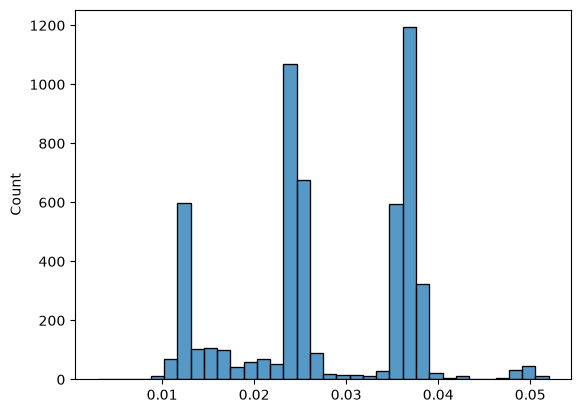

In [210]:
sns.histplot(squeezed_intervals);

In [189]:
orphans_df = key_df[key_df["Up"].isna()]
orphans_df["Key"].unique()

<ArrowStringArray>
['tab']
Length: 1, dtype: str

In [191]:
tab_only_df = key_df[key_df["Key"] == "tab"]
tab_only_df.isna().sum()

Key                0
Down               0
Epochs             0
Up              3169
Release Only      19
dtype: int64

In [212]:
next_key_df = key_df.groupby(level=LEVELS).shift(-1).rename({
    "Key": "Next Key",
    "Down": "Next Down",
    "Up": "Next Up"
    }, axis=1)

key_df = key_df.join(next_key_df[["Next Key", "Next Down", "Next Up"]])

In [213]:
key_df["Dwell Time"] = key_df["Up"] - key_df["Down"]
key_df["UU"] = key_df["Next Up"] - key_df["Up"]
key_df["DD"] = key_df["Next Down"] - key_df["Down"]
key_df["Flight Time"] = key_df["Next Down"] - key_df["Up"]
key_df

Key          Down                Epochs  \
User ID Is Genuine Test ID                                                    
1       False      1       0      shift  1.644176e+09  [1644175533.9525526]   
                           1          m  1.644176e+09  [1644175534.0420332]   
                           2          r  1.644176e+09   [1644175534.257084]   
                           3          s  1.644176e+09  [1644175534.4087963]   
                           4   spacebar  1.644176e+09  [1644175534.5358133]   
...                                 ...           ...                   ...   
88      True       10      41         1  1.649930e+09  [1649930364.1611965]   
                           42         0  1.649930e+09   [1649930364.882375]   
                           43       tab  1.649930e+09   [1649930366.013663]   
                           44         2  1.649930e+09  [1649930366.3227415]   
                           45         3  1.649930e+09   [1649930366.718838]   

                                         Up Release Only  Next Key  \
User ID Is Genuine Test ID                                           
1       False      1       0   1.644176e+09          NaN         m   
                           1   1.644176e+09          NaN         r   
                           2   1.644176e+09          NaN         s   
                           3   1.644176e+09          NaN  spacebar   
                           4   1.644176e+09          NaN    rshift   
...                                     ...          ...       ...   
88      True       10      41  1.649930e+09          NaN         0   
                           42  1.649930e+09          NaN       tab   
                           43           NaN         True         2   
                           44  1.649930e+09          NaN         3   
                           45  1.649930e+09          NaN       NaN   

                                  Next Down       Next Up  Dwell Time  \
User ID Is Genuine Test ID                                              
1       False      1       0   1.644176e+09  1.644176e+09    0.201804   
                           1   1.644176e+09  1.644176e+09    0.062926   
                           2   1.644176e+09  1.644176e+09    0.063342   
                           3   1.644176e+09  1.644176e+09    0.100993   
                           4   1.644176e+09  1.644176e+09    0.075246   
...                                     ...           ...         ...   
88      True       10      41  1.649930e+09  1.649930e+09    0.193050   
                           42  1.649930e+09           NaN    0.103026   
                           43  1.649930e+09  1.649930e+09         NaN   
                           44  1.649930e+09  1.649930e+09    0.205047   
                           45           NaN           NaN    0.193049   

                                     UU        DD  Flight Time  
User ID Is Genuine Test ID                                      
1       False      1       0  -0.049397  0.089481    -0.112323  
                           1   0.215467  0.215051     0.152125  
                           2   0.189364  0.151712     0.088371  
                           3   0.101269  0.127017     0.026024  
                           4   0.315332  0.176681     0.101435  
...                                 ...       ...          ...  
88      True       10      41  0.631155  0.721179     0.528128  
                           42       NaN  1.131288     1.028262  
                           43       NaN  0.309078          NaN  
                           44  0.384098  0.396096     0.191049  
                           45       NaN       NaN          NaN  

[84955 rows x 12 columns]

In [214]:
pressed_key_df = key_df[key_df["Key"].isin(["capslock", "enter", "spacebar"])]
other_keys_test_level = pressed_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Up"].count().unstack()
other_keys_test_level

Key                         capslock  enter  spacebar
User ID Is Genuine Test ID                           
1       False      1             NaN    NaN       2.0
                   2             NaN    NaN       2.0
                   3             8.0    NaN       2.0
                   4             NaN    NaN       2.0
                   5             NaN    NaN       2.0
...                              ...    ...       ...
88      True       6             NaN    NaN       2.0
                   7             NaN    NaN       3.0
                   8             NaN    NaN       2.0
                   9             2.0    NaN       2.0
                   10            NaN    NaN       2.0

[1759 rows x 3 columns]

In [215]:
key_test_level = key_df.groupby(level=LEVELS).agg(
    Dwell_median=("Dwell Time", "median"),
    Dwell_iqr=("Dwell Time", lambda x: x.quantile(.75) - x.quantile(.25)),
    Flight_mean=("Flight Time", "mean"),
    Flight_std=("Flight Time", "std")
)
key_test_level

Dwell_median  Dwell_iqr  Flight_mean  Flight_std
User ID Is Genuine Test ID                                                  
1       False      1            0.075183   0.024578     0.455992    0.743005
                   2            0.086801   0.014753     0.722630    0.979369
                   3            0.073625   0.025564     0.450286    0.751870
                   4            0.121413   0.021379     0.774072    1.224228
                   5            0.170910   0.049758     0.223364    0.470348
...                                  ...        ...          ...         ...
88      True       6            0.142035   0.059016     0.539939    0.607880
                   7            0.141037   0.053761     0.585892    0.645390
                   8            0.141034   0.053261     0.484341    0.439022
                   9            0.141034   0.059767     0.650253    0.634670
                   10           0.147538   0.066015     0.496808    0.442216

[1760 rows x 4 columns]

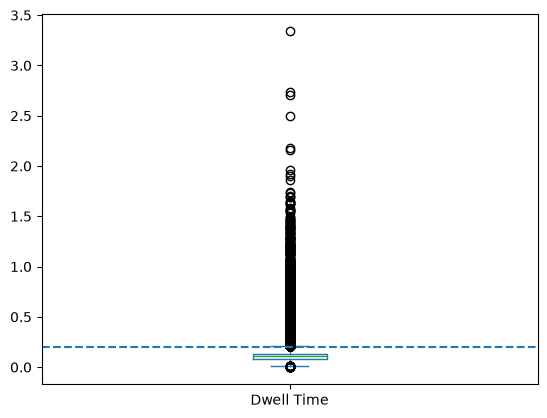

In [216]:
ax = key_df["Dwell Time"].plot(kind="box")
plt.axhline(0.2, linestyle="--", label="0.3 s");

In [217]:
shift_key_df = key_df[key_df["Key"].isin(SHIFT_KEYS)]
shift_key_df.groupby(level=LEVELS).agg(
    Shift_Dwell_mean=("Dwell Time", "mean"),
    Shift_Dwell_std=("Dwell Time", "std")
)

Shift_Dwell_mean  Shift_Dwell_std
User ID Is Genuine Test ID                                   
1       False      1                0.192708         0.026917
                   2                0.675441         0.397550
                   4                0.321364         0.014152
                   5                0.379624         0.065181
                   6                0.236703         0.037387
...                                      ...              ...
88      True       6                0.308744         0.061664
                   7                0.335087         0.042940
                   8                0.326757         0.054252
                   9                0.331418         0.027398
                   10               0.334749         0.123467

[872 rows x 2 columns]

In [218]:
correction_key_df = key_df[key_df["Key"].isin(CORRECTION_KEYS)]
shift_key_df.groupby(level=LEVELS).agg(
    Corr_Dwell_mean=("Dwell Time", "mean"),
    Corr_Dwell_std=("Dwell Time", "std"),
    Corr_count=("Dwell Time", "count")
)

Corr_Dwell_mean  Corr_Dwell_std  Corr_count
User ID Is Genuine Test ID                                             
1       False      1               0.192708        0.026917           3
                   2               0.675441        0.397550           3
                   4               0.321364        0.014152           3
                   5               0.379624        0.065181           3
                   6               0.236703        0.037387           3
...                                     ...             ...         ...
88      True       6               0.308744        0.061664           3
                   7               0.335087        0.042940           3
                   8               0.326757        0.054252           3
                   9               0.331418        0.027398           3
                   10              0.334749        0.123467           3

[872 rows x 3 columns]